In [1]:
# ============================================================
# KWERIMOTO: ENGINE SOUND CLASSIFICATION (FINAL)
# ============================================================


# ===== INSTALL + IMPORTS =====
!pip -q install librosa soundfile numpy pandas scikit-learn \
    xgboost matplotlib seaborn joblib huggingface_hub

from pathlib import Path
from collections import Counter
import json
import shutil
import warnings

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from huggingface_hub import snapshot_download
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, classification_report, confusion_matrix
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
CLASSES = ["healthy", "engine_knock", "misfire"]


In [2]:
# ===== LOAD DATASET =====
REPO_ID = "rayyyyy007/kwerimoto-engine-sounds"
root = Path(snapshot_download(repo_id=REPO_ID, repo_type="dataset"))

manifest_path = root / "manifest.csv"
if not manifest_path.exists():
    raise FileNotFoundError("manifest.csv not found in the dataset.")

manifest = pd.read_csv(manifest_path, keep_default_na=False)

required = {"file_name", "label", "split", "source_recording"}
if not required.issubset(manifest.columns):
    raise ValueError(f"Manifest must contain {required}")
if set(manifest["label"]) != set(CLASSES):
    raise ValueError(f"Unexpected labels: {sorted(manifest['label'].unique())}")
if not {"train", "validation", "test", "real_test"}.issubset(set(manifest["split"])):
    raise ValueError("One or more expected splits are missing.")

print("Total recordings:", len(manifest))
print(pd.crosstab(manifest["split"], manifest["label"]))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1074 files:   0%|          | 0/1074 [00:00<?, ?it/s]

Total recordings: 1067
label       engine_knock  healthy  misfire
split                                     
real_test             38        0        0
test                  85       53       16
train                399      246       76
validation            86       52       16


In [3]:
# ===== FEATURE EXTRACTION (100 features) =====
SAMPLE_RATE = 16000
N_MFCC = 20
N_FFT = 1024
HOP_LENGTH = 256

FEATURE_NAMES = (
    [f"mfcc_{i+1}_mean" for i in range(N_MFCC)]
    + [f"mfcc_{i+1}_std" for i in range(N_MFCC)]
    + [f"dmfcc_{i+1}_mean" for i in range(N_MFCC)]
    + [f"dmfcc_{i+1}_std" for i in range(N_MFCC)]
    + ["centroid_mean", "centroid_std", "rolloff_mean", "rolloff_std",
       "bandwidth_mean", "bandwidth_std", "flatness_mean", "flatness_std",
       "zcr_mean", "zcr_std", "rms_variation", "rms_peakiness",
       "onset_mean", "onset_std", "onset_max", "onsets_per_sec",
       "band_0_500", "band_500_1500", "band_1500_3000", "band_3000_8000"]
)


def extract_features(file_path):
    audio, sr = sf.read(file_path, dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if audio.ndim != 1 or len(audio) < 1024:
        raise ValueError("Audio is empty or too short.")
    if sr != SAMPLE_RATE:
        audio = librosa.resample(audio, orig_sr=sr, target_sr=SAMPLE_RATE)
    if not np.all(np.isfinite(audio)):
        raise ValueError("Audio contains invalid values.")

    # Scale to unit RMS so microphone gain/distance cannot leak into features.
    audio = audio / (np.sqrt(np.mean(audio ** 2)) + 1e-8)

    S = np.abs(librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LENGTH))
    mfcc = librosa.feature.mfcc(y=audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                n_fft=N_FFT, hop_length=HOP_LENGTH)

    # Delta width must fit short clips.
    n_frames = mfcc.shape[1]
    width = min(9, n_frames if n_frames % 2 == 1 else n_frames - 1)
    delta = (librosa.feature.delta(mfcc, width=width)
             if width >= 3 else np.zeros_like(mfcc))

    rms = librosa.feature.rms(S=S, frame_length=N_FFT)[0]
    centroid = librosa.feature.spectral_centroid(S=S, sr=SAMPLE_RATE)[0]
    rolloff = librosa.feature.spectral_rolloff(S=S, sr=SAMPLE_RATE)[0]
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=SAMPLE_RATE)[0]
    flatness = librosa.feature.spectral_flatness(S=S)[0]
    zcr = librosa.feature.zero_crossing_rate(
        audio, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]

    onset = librosa.onset.onset_strength(
        y=audio, sr=SAMPLE_RATE, hop_length=HOP_LENGTH)
    n_onsets = len(librosa.onset.onset_detect(
        onset_envelope=onset, sr=SAMPLE_RATE, hop_length=HOP_LENGTH))
    duration = len(audio) / SAMPLE_RATE

    # Share of energy in four frequency bands.
    freqs = librosa.fft_frequencies(sr=SAMPLE_RATE, n_fft=N_FFT)
    power = (S ** 2).sum(axis=1)
    edges = [0, 500, 1500, 3000, SAMPLE_RATE / 2 + 1]
    bands = np.array([power[(freqs >= lo) & (freqs < hi)].sum()
                      for lo, hi in zip(edges[:-1], edges[1:])])
    bands = bands / (bands.sum() + 1e-12)

    def ms(x):
        return [np.mean(x), np.std(x)]

    feats = np.concatenate([
        np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
        np.mean(delta, axis=1), np.std(delta, axis=1),
        ms(centroid), ms(rolloff), ms(bandwidth), ms(flatness), ms(zcr),
        [np.std(rms) / (np.mean(rms) + 1e-8),
         np.max(rms) / (np.mean(rms) + 1e-8)],
        [np.mean(onset), np.std(onset), np.max(onset), n_onsets / duration],
        bands
    ])
    assert len(feats) == len(FEATURE_NAMES)
    return feats.astype(np.float32)

In [4]:
# ===== EXTRACT FEATURES FOR EACH SPLIT (1-3 min) =====
X, y, meta = {}, {}, {}

for split in ["train", "validation", "test", "real_test"]:
    rows = manifest[manifest["split"] == split]
    X_list, y_list, meta_list, skipped = [], [], [], []

    for _, row in rows.iterrows():
        try:
            path = root / row["file_name"]
            if not path.is_file():
                raise FileNotFoundError(str(path))
            X_list.append(extract_features(path))
            y_list.append(row["label"])
            meta_list.append(row.to_dict())
        except Exception as e:
            skipped.append((row["file_name"], str(e)))

    if not X_list:
        raise ValueError(f"No usable recordings in split {split}.")

    X[split] = np.vstack(X_list)
    y[split] = np.asarray(y_list)
    meta[split] = pd.DataFrame(meta_list)
    print(f"{split:11s} {X[split].shape} {dict(Counter(y_list))} "
          f"skipped={len(skipped)}")
    if skipped:
        print("  first skipped:", skipped[:3])

label_encoder = LabelEncoder().fit(CLASSES)
y_train = label_encoder.transform(y["train"])
y_val = label_encoder.transform(y["validation"])
y_test = label_encoder.transform(y["test"])
print("Class mapping:", dict(enumerate(label_encoder.classes_)))


train       (721, 100) {'engine_knock': 399, 'healthy': 246, 'misfire': 76} skipped=0
validation  (154, 100) {'engine_knock': 86, 'healthy': 52, 'misfire': 16} skipped=0
test        (154, 100) {'engine_knock': 85, 'healthy': 53, 'misfire': 16} skipped=0
real_test   (38, 100) {'engine_knock': 38} skipped=0
Class mapping: {0: np.str_('engine_knock'), 1: np.str_('healthy'), 2: np.str_('misfire')}


Best iteration: 310


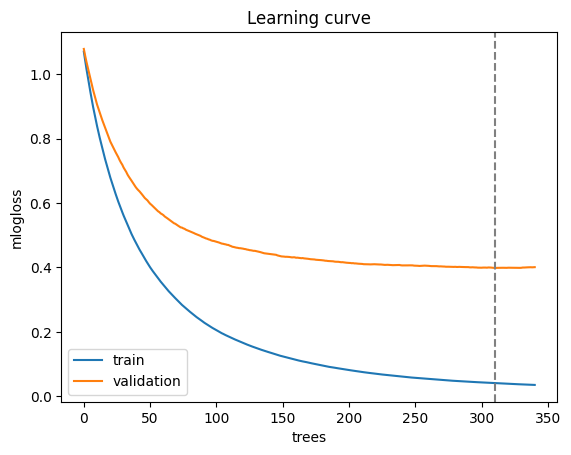

TRAIN acc: 1.0
VAL   acc: 0.8312
Accuracy:          0.8961
Balanced accuracy: 0.9183
Macro F1:          0.8960

              precision    recall  f1-score   support

engine_knock       0.93      0.91      0.92        85
     healthy       0.87      0.85      0.86        53
     misfire       0.84      1.00      0.91        16

    accuracy                           0.90       154
   macro avg       0.88      0.92      0.90       154
weighted avg       0.90      0.90      0.90       154



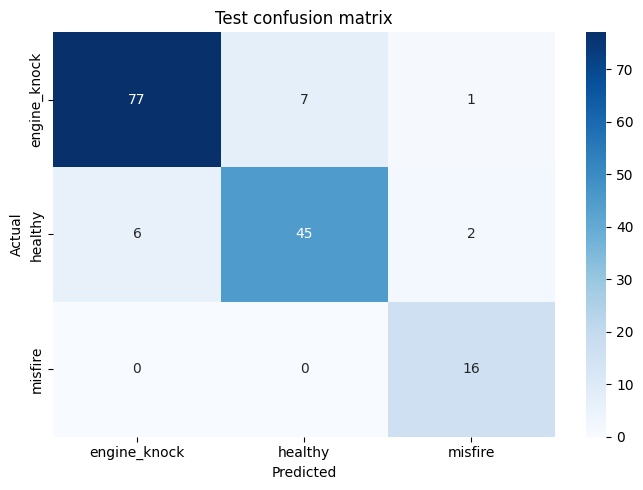

Real-knock recall: 0.9211
engine_knock    35
healthy          3
Name: count, dtype: int64


In [5]:
# ===== TRAIN XGBOOST =====
PARAMS = dict(
    objective="multi:softprob", num_class=len(CLASSES),
    max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=2, reg_lambda=1.0, eval_metric="mlogloss",
    random_state=SEED, n_jobs=-1, tree_method="hist"
)

model = XGBClassifier(**PARAMS, n_estimators=500, early_stopping_rounds=30)
model.fit(
    X["train"], y_train,
    sample_weight=compute_sample_weight("balanced", y_train),  # offsets rare misfire
    eval_set=[(X["train"], y_train), (X["validation"], y_val)],  # validation must be last
    verbose=False
)
N_TREES = int(model.best_iteration) + 1
print("Best iteration:", model.best_iteration)

# Learning curve: a growing train/validation gap means overfitting.
res = model.evals_result()
plt.plot(res["validation_0"]["mlogloss"], label="train")
plt.plot(res["validation_1"]["mlogloss"], label="validation")
plt.axvline(model.best_iteration, ls="--", c="gray")
plt.xlabel("trees"); plt.ylabel("mlogloss"); plt.legend()
plt.title("Learning curve"); plt.show()

print("TRAIN acc:", round(accuracy_score(y_train, model.predict(X["train"])), 4))
print("VAL   acc:", round(accuracy_score(y_val, model.predict(X["validation"])), 4))


# ===== TEST + REAL-KNOCK EVALUATION =====
# The test set is used for reporting only, never for tuning.
test_pred = model.predict(X["test"])
test_accuracy = accuracy_score(y_test, test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Balanced accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}\n")
print(classification_report(
    y_test, test_pred, labels=np.arange(len(CLASSES)),
    target_names=label_encoder.classes_, zero_division=0))

plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_test, test_pred, labels=np.arange(len(CLASSES))),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Test confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# real_test holds knock only: this is knock recall, NOT a false-alarm rate.
real_pred = label_encoder.inverse_transform(model.predict(X["real_test"]))
real_knock_recall = float(np.mean(real_pred == "engine_knock"))
print(f"Real-knock recall: {real_knock_recall:.4f}")
print(pd.Series(real_pred).value_counts())

In [6]:
# ===== GROUPED 5-FOLD CROSS-VALIDATION =====
# Most reliable accuracy estimate: clips from one recording never span
# train and test folds.
X_all = np.vstack([X["train"], X["validation"]])
y_all = np.concatenate([y_train, y_val])
groups = pd.concat([meta["train"], meta["validation"]],
                   ignore_index=True)["source_recording"].values

oof = np.zeros_like(y_all)
accs, bals, f1s, recs = [], [], [], []
folds = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
for tr, te in folds.split(X_all, y_all, groups):
    m = XGBClassifier(**PARAMS, n_estimators=N_TREES)
    m.fit(X_all[tr], y_all[tr],
          sample_weight=compute_sample_weight("balanced", y_all[tr]))
    p = m.predict(X_all[te])
    oof[te] = p
    accs.append(accuracy_score(y_all[te], p))
    bals.append(balanced_accuracy_score(y_all[te], p))
    f1s.append(f1_score(y_all[te], p, average="macro"))
    recs.append(recall_score(y_all[te], p, average=None, labels=[0, 1, 2]))
recs = np.array(recs)

cv_accuracy, cv_macro_f1 = float(np.mean(accs)), float(np.mean(f1s))
print(f"accuracy     {cv_accuracy:.3f} ± {np.std(accs):.3f}")
print(f"balanced acc {np.mean(bals):.3f} ± {np.std(bals):.3f}")
print(f"macro F1     {cv_macro_f1:.3f} ± {np.std(f1s):.3f}")
for i, c in enumerate(label_encoder.classes_):
    print(f"recall {c:13s} {recs[:, i].mean():.3f} ± {recs[:, i].std():.3f}")
print(confusion_matrix(y_all, oof))

accuracy     0.869 ± 0.015
balanced acc 0.857 ± 0.037
macro F1     0.848 ± 0.027
recall engine_knock  0.917 ± 0.032
recall healthy       0.785 ± 0.072
recall misfire       0.870 ± 0.102
[[445  34   6]
 [ 47 235  16]
 [  6   6  80]]


In [7]:
#===== KNOCK THRESHOLD (CHOOSE ON VALIDATION) =====
# Lower threshold = fewer missed knocks, more false alarms.
def predict_with_threshold(proba, thr):
    other = 1 + proba[:, 1:].argmax(axis=1)       # healthy or misfire
    return np.where(proba[:, 0] >= thr, 0, other)  # knock above threshold

proba_val = model.predict_proba(X["validation"])
print("thr | VAL knock recall | VAL healthy recall | VAL macro F1")
for thr in [0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
    p = predict_with_threshold(proba_val, thr)
    r = recall_score(y_val, p, average=None, labels=[0, 1, 2])
    print(f"{thr:.2f} | {r[0]:.3f} | {r[1]:.3f} | "
          f"{f1_score(y_val, p, average='macro'):.3f}")

THRESHOLD = 0.5  # set from the table above, then re-run this cell

p = predict_with_threshold(model.predict_proba(X["test"]), THRESHOLD)
print(f"\nTEST @ threshold {THRESHOLD}")
print(classification_report(y_test, p, target_names=label_encoder.classes_,
                            zero_division=0))
real_thr_recall = float((predict_with_threshold(
    model.predict_proba(X["real_test"]), THRESHOLD) == 0).mean())
print("Real-knock recall:", round(real_thr_recall, 3))



thr | VAL knock recall | VAL healthy recall | VAL macro F1
0.20 | 0.965 | 0.712 | 0.808
0.25 | 0.953 | 0.712 | 0.803
0.30 | 0.919 | 0.731 | 0.795
0.35 | 0.895 | 0.731 | 0.801
0.40 | 0.895 | 0.731 | 0.801
0.50 | 0.872 | 0.808 | 0.828

TEST @ threshold 0.5
              precision    recall  f1-score   support

engine_knock       0.93      0.91      0.92        85
     healthy       0.87      0.85      0.86        53
     misfire       0.84      1.00      0.91        16

    accuracy                           0.90       154
   macro avg       0.88      0.92      0.90       154
weighted avg       0.90      0.90      0.90       154

Real-knock recall: 0.921


       feature  importance
bandwidth_mean    0.099724
 centroid_mean    0.077707
  rolloff_mean    0.049711
onsets_per_sec    0.037154
  dmfcc_1_mean    0.023076
     onset_max    0.020533
  mfcc_14_mean    0.020223
band_1500_3000    0.020032
  mfcc_10_mean    0.018964
   mfcc_3_mean    0.016786
band_3000_8000    0.016139
  dmfcc_2_mean    0.016003
   mfcc_2_mean    0.013814
   mfcc_1_mean    0.012904
    mfcc_3_std    0.012664


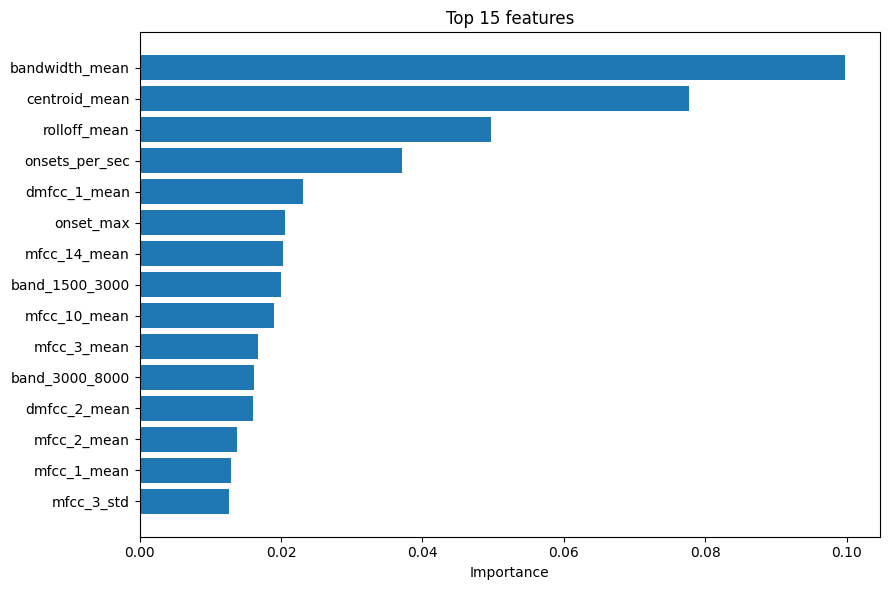

In [8]:
# ===== FEATURE IMPORTANCE =====
importance_df = pd.DataFrame({
    "feature": FEATURE_NAMES, "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df.head(15).to_string(index=False))
top = importance_df.head(15).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance"])
plt.title("Top 15 features"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()

In [10]:
# ===== SAVE MODEL PACKAGE + ZIP =====
OUTPUT_DIR = Path("/content/kwerimoto_model")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, OUTPUT_DIR / "kwerimoto_xgboost.joblib")
joblib.dump(label_encoder, OUTPUT_DIR / "kwerimoto_label_encoder.joblib")

config = {
    "model": "XGBoost",
    "features": "MFCC + delta MFCC + spectral + onset + band energy (100)",
    "feature_names": FEATURE_NAMES,
    "audio_normalization": "unit RMS per clip",
    "sample_rate": SAMPLE_RATE,
    "n_mfcc": N_MFCC,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "classes": label_encoder.classes_.tolist(),
    "knock_threshold": THRESHOLD,
    "class_weighting": "balanced",
    "best_iteration": int(model.best_iteration),
    "cv_accuracy": cv_accuracy,
    "cv_macro_f1": cv_macro_f1,
    "test_accuracy": float(test_accuracy),
    "test_balanced_accuracy": float(test_balanced_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "real_knock_recall": real_knock_recall,
}
with open(OUTPUT_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

with open(OUTPUT_DIR / "evaluation_report.txt", "w") as f:
    f.write("KweriMoto rich features + XGBoost\n")
    f.write(f"CV accuracy: {cv_accuracy:.4f} | CV macro F1: {cv_macro_f1:.4f}\n")
    f.write(f"Test accuracy: {test_accuracy:.4f} | "
            f"Balanced: {test_balanced_accuracy:.4f} | "
            f"Macro F1: {test_macro_f1:.4f}\n\n")
    f.write(classification_report(
        y_test, test_pred, labels=np.arange(len(CLASSES)),
        target_names=label_encoder.classes_, zero_division=0))

importance_df.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

from google.colab import files
zip_path = shutil.make_archive("/content/kwerimoto_model", "zip",
                               root_dir=OUTPUT_DIR)
files.download(zip_path)

print("\nPIPELINE FINISHED.")

# ===== PREDICT ON A NEW RECORDING =====
def predict_file(audio_path, threshold=THRESHOLD):
    feats = extract_features(audio_path).reshape(1, -1)
    proba = model.predict_proba(feats)
    label = label_encoder.inverse_transform(
        predict_with_threshold(proba, threshold))[0]
    return label, dict(zip(label_encoder.classes_, proba[0].round(3)))

# Example (upload a clip first):
# print(predict_file("/content/my_engine_clip.wav"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PIPELINE FINISHED.
